In [ ]:
import copy
import time
from collections import OrderedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch', torch.__version__, '| device:', device,
      '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU only')

PyTorch 2.14.1+cu130 | device: cuda | Tesla T4


In [ ]:
SEED = 42
MAX_EPOCHS = 100
PATIENCE = 8
BATCH_SIZE = 128
LR = 1e-3
N_IN = 3 * 32 * 32
N_CLASSES = 10

In [ ]:
def load_cifar10():
    try:
        from torchvision import datasets
        train_ds = datasets.CIFAR10('./data', train=True, download=True)
        test_ds = datasets.CIFAR10('./data', train=False, download=True)
        return train_ds.data, np.array(train_ds.targets), test_ds.data, np.array(test_ds.targets)
    except Exception as e:
        print('torchvision download not available (' + type(e).__name__ + '), using local copy')
        d = np.load('cifar10_local.npz')
        return d['Xtr'], d['ytr'], d['Xte'], d['yte']

raw_train_x, raw_train_y, raw_test_x, raw_test_y = load_cifar10()
print('Training images:', raw_train_x.shape, ' Test images:', raw_test_x.shape)
print('Images per class (train):', np.bincount(raw_train_y))

100%|██████████| 170M/170M [14:33<00:00, 195kB/s]


Training images: (50000, 32, 32, 3)  Test images: (10000, 32, 32, 3)
Images per class (train): [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


In [ ]:
def to_tensor(images):
    x = torch.from_numpy(images).permute(0, 3, 1, 2).contiguous().float()
    return x.div_(255.0)


torch.manual_seed(SEED)
x_all = to_tensor(raw_train_x)
y_all = torch.from_numpy(raw_train_y).long()

n_samples = len(x_all)
n_val = int(0.1 * n_samples)
shuffled_indices = torch.randperm(n_samples)
train_indices = shuffled_indices[:-n_val]
val_indices = shuffled_indices[-n_val:]

X_train, y_train = x_all[train_indices], y_all[train_indices]
X_val, y_val = x_all[val_indices], y_all[val_indices]
del x_all
X_test, y_test = to_tensor(raw_test_x), torch.from_numpy(raw_test_y).long()

mean = X_train.mean(dim=(0, 2, 3), keepdim=True)
std = X_train.std(dim=(0, 2, 3), keepdim=True)
for x in (X_train, X_val, X_test):
    x.sub_(mean).div_(std)

X_train, y_train = X_train.to(device), y_train.to(device)
X_val, y_val = X_val.to(device), y_val.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

print('Train:', tuple(X_train.shape), ' Validation:', tuple(X_val.shape), ' Test:', tuple(X_test.shape))

Train: (45000, 3, 32, 32)  Validation: (5000, 3, 32, 32)  Test: (10000, 3, 32, 32)


In [ ]:
def build_model(n_in, hidden, activation, n_out):
    layers = [('flatten', nn.Flatten())]
    d = n_in
    for i, h in enumerate(hidden, start=1):
        layers.append((f'hidden_linear{i}', nn.Linear(d, h)))
        layers.append((f'hidden_activation{i}', activation()))
        d = h
    layers.append(('output_linear', nn.Linear(d, n_out)))
    return nn.Sequential(OrderedDict(layers))


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def evaluate(model, X, y, loss_fn, chunk=5000):
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for i in range(0, len(X), chunk):
            out = model(X[i:i + chunk])
            total_loss += loss_fn(out, y[i:i + chunk]).item() * len(out)
            correct += (out.argmax(dim=1) == y[i:i + chunk]).sum().item()
    return total_loss / len(X), correct / len(X)

In [ ]:
results = {}
histories = {}


def train_model(name, hidden, activation, print_every=5):
    torch.manual_seed(SEED)
    model = build_model(N_IN, hidden, activation, N_CLASSES).to(device)
    optimizer = optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.CrossEntropyLoss()

    hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_loss, best_epoch, best_state, wait = float('inf'), 0, None, 0

    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.time()

    for epoch in range(1, MAX_EPOCHS + 1):
        perm = torch.randperm(len(X_train), device=device)
        run_loss, run_correct = 0.0, 0
        for i in range(0, len(X_train), BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            output = model(X_train[idx])
            loss_train = loss_fn(output, y_train[idx])

            optimizer.zero_grad()
            loss_train.backward()
            optimizer.step()

            run_loss += loss_train.item() * len(idx)
            run_correct += (output.argmax(dim=1) == y_train[idx]).sum().item()

        loss_val, acc_val = evaluate(model, X_val, y_val, loss_fn)
        hist['train_loss'].append(run_loss / len(X_train))
        hist['train_acc'].append(run_correct / len(X_train))
        hist['val_loss'].append(loss_val)
        hist['val_acc'].append(acc_val)

        if loss_val < best_val_loss:
            best_val_loss, best_epoch, wait = loss_val, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1

        if epoch == 1 or epoch % print_every == 0:
            print(f"Epoch {epoch}, Training loss {hist['train_loss'][-1]:.4f},"
                  f" Validation loss {loss_val:.4f}, Training acc {hist['train_acc'][-1]:.4f},"
                  f" Validation acc {acc_val:.4f}")
        if wait >= PATIENCE:
            print(f'Early stopping at epoch {epoch} (best epoch: {best_epoch})')
            break

    if device.type == 'cuda':
        torch.cuda.synchronize()
    train_time = time.time() - start


    model.load_state_dict(best_state)
    train_loss, train_acc = evaluate(model, X_train, y_train, loss_fn)
    _, val_acc = evaluate(model, X_val, y_val, loss_fn)
    test_loss, test_acc = evaluate(model, X_test, y_test, loss_fn)

    row = {'Experiment': name, 'Hidden layers': len(hidden), 'Neurons per layer': hidden[0],
           'Activation': activation.__name__, 'Parameters': count_parameters(model),
           'Epochs run': epoch, 'Best epoch': best_epoch, 'Train time (s)': round(train_time, 1),
           'Train loss': train_loss, 'Train acc': train_acc, 'Val acc': val_acc,
           'Test loss': test_loss, 'Test acc': test_acc}
    results[name] = row
    histories[name] = hist
    print(model)
    return pd.DataFrame([row]).T

In [ ]:
train_model('1.a Baseline (2 hidden, ReLU)', [256, 256], nn.ReLU)

Epoch 1, Training loss 1.6551, Validation loss 1.5258, Training acc 0.4126, Validation acc 0.4612
Epoch 5, Training loss 1.1613, Validation loss 1.3935, Training acc 0.5900, Validation acc 0.5272
Epoch 10, Training loss 0.8135, Validation loss 1.5406, Training acc 0.7115, Validation acc 0.5118
Early stopping at epoch 12 (best epoch: 4)
Sequential(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (hidden_linear1): Linear(in_features=3072, out_features=256, bias=True)
  (hidden_activation1): ReLU()
  (hidden_linear2): Linear(in_features=256, out_features=256, bias=True)
  (hidden_activation2): ReLU()
  (output_linear): Linear(in_features=256, out_features=10, bias=True)
)


,0
Experiment,"1.a Baseline (2 hidden, ReLU)"
Hidden layers,2
Neurons per layer,256
Activation,ReLU
Parameters,855050
Epochs run,12
Best epoch,4
Train time (s),8.3
Train loss,1.12798
Train acc,0.608156


In [ ]:
train_model('1.b Deeper (4 hidden, ReLU)', [256] * 4, nn.ReLU)

Epoch 1, Training loss 1.6980, Validation loss 1.5502, Training acc 0.3950, Validation acc 0.4462
Epoch 5, Training loss 1.1677, Validation loss 1.3692, Training acc 0.5828, Validation acc 0.5292
Epoch 10, Training loss 0.8173, Validation loss 1.5259, Training acc 0.7042, Validation acc 0.5216
Early stopping at epoch 13 (best epoch: 5)
Sequential(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (hidden_linear1): Linear(in_features=3072, out_features=256, bias=True)
  (hidden_activation1): ReLU()
  (hidden_linear2): Linear(in_features=256, out_features=256, bias=True)
  (hidden_activation2): ReLU()
  (hidden_linear3): Linear(in_features=256, out_features=256, bias=True)
  (hidden_activation3): ReLU()
  (hidden_linear4): Linear(in_features=256, out_features=256, bias=True)
  (hidden_activation4): ReLU()
  (output_linear): Linear(in_features=256, out_features=10, bias=True)
)


,0
Experiment,"1.b Deeper (4 hidden, ReLU)"
Hidden layers,4
Neurons per layer,256
Activation,ReLU
Parameters,986634
Epochs run,13
Best epoch,5
Train time (s),10.2
Train loss,1.053874
Train acc,0.626867


In [ ]:
train_model('2.a Deep (10 hidden, ReLU)', [256] * 10, nn.ReLU)

Epoch 1, Training loss 1.9276, Validation loss 1.7894, Training acc 0.2538, Validation acc 0.3066
Epoch 5, Training loss 1.3887, Validation loss 1.4764, Training acc 0.5022, Validation acc 0.4858
Epoch 10, Training loss 1.0701, Validation loss 1.4964, Training acc 0.6186, Validation acc 0.5100
Epoch 15, Training loss 0.8326, Validation loss 1.6022, Training acc 0.7048, Validation acc 0.5098
Early stopping at epoch 16 (best epoch: 8)
Sequential(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (hidden_linear1): Linear(in_features=3072, out_features=256, bias=True)
  (hidden_activation1): ReLU()
  (hidden_linear2): Linear(in_features=256, out_features=256, bias=True)
  (hidden_activation2): ReLU()
  (hidden_linear3): Linear(in_features=256, out_features=256, bias=True)
  (hidden_activation3): ReLU()
  (hidden_linear4): Linear(in_features=256, out_features=256, bias=True)
  (hidden_activation4): ReLU()
  (hidden_linear5): Linear(in_features=256, out_features=256, bias=True)
  (hidden_activ

,0
Experiment,"2.a Deep (10 hidden, ReLU)"
Hidden layers,10
Neurons per layer,256
Activation,ReLU
Parameters,1381386
Epochs run,16
Best epoch,8
Train time (s),20.7
Train loss,1.08735
Train acc,0.617178


In [ ]:
train_model('2.b Exp1 Wide (2x512, ReLU)', [512, 512], nn.ReLU)

Epoch 1, Training loss 1.6568, Validation loss 1.5369, Training acc 0.4111, Validation acc 0.4540
Epoch 5, Training loss 1.1507, Validation loss 1.3921, Training acc 0.5934, Validation acc 0.5220
Epoch 10, Training loss 0.7698, Validation loss 1.6176, Training acc 0.7273, Validation acc 0.5164
Early stopping at epoch 13 (best epoch: 5)
Sequential(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (hidden_linear1): Linear(in_features=3072, out_features=512, bias=True)
  (hidden_activation1): ReLU()
  (hidden_linear2): Linear(in_features=512, out_features=512, bias=True)
  (hidden_activation2): ReLU()
  (output_linear): Linear(in_features=512, out_features=10, bias=True)
)


,0
Experiment,"2.b Exp1 Wide (2x512, ReLU)"
Hidden layers,2
Neurons per layer,512
Activation,ReLU
Parameters,1841162
Epochs run,13
Best epoch,5
Train time (s),9.6
Train loss,1.020292
Train acc,0.639778


In [ ]:
train_model('2.b Exp2 Sigmoid (2x256)', [256, 256], nn.Sigmoid)

Epoch 1, Training loss 1.8214, Validation loss 1.7032, Training acc 0.3524, Validation acc 0.4072
Epoch 5, Training loss 1.4526, Validation loss 1.5535, Training acc 0.4894, Validation acc 0.4594
Epoch 10, Training loss 1.2430, Validation loss 1.5043, Training acc 0.5623, Validation acc 0.4676
Epoch 15, Training loss 1.0638, Validation loss 1.5413, Training acc 0.6270, Validation acc 0.4742
Early stopping at epoch 18 (best epoch: 10)
Sequential(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (hidden_linear1): Linear(in_features=3072, out_features=256, bias=True)
  (hidden_activation1): Sigmoid()
  (hidden_linear2): Linear(in_features=256, out_features=256, bias=True)
  (hidden_activation2): Sigmoid()
  (output_linear): Linear(in_features=256, out_features=10, bias=True)
)


,0
Experiment,2.b Exp2 Sigmoid (2x256)
Hidden layers,2
Neurons per layer,256
Activation,Sigmoid
Parameters,855050
Epochs run,18
Best epoch,10
Train time (s),11.2
Train loss,1.173563
Train acc,0.588356


In [ ]:
train_model('2.b Exp3 Tanh (2x256)', [256, 256], nn.Tanh)

Epoch 1, Training loss 1.7999, Validation loss 1.7227, Training acc 0.3710, Validation acc 0.4026
Epoch 5, Training loss 1.5267, Validation loss 1.6074, Training acc 0.4688, Validation acc 0.4460
Epoch 10, Training loss 1.3590, Validation loss 1.5529, Training acc 0.5267, Validation acc 0.4692
Epoch 15, Training loss 1.2215, Validation loss 1.5618, Training acc 0.5742, Validation acc 0.4694
Epoch 20, Training loss 1.0861, Validation loss 1.5849, Training acc 0.6224, Validation acc 0.4716
Early stopping at epoch 20 (best epoch: 12)
Sequential(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (hidden_linear1): Linear(in_features=3072, out_features=256, bias=True)
  (hidden_activation1): Tanh()
  (hidden_linear2): Linear(in_features=256, out_features=256, bias=True)
  (hidden_activation2): Tanh()
  (output_linear): Linear(in_features=256, out_features=10, bias=True)
)


,0
Experiment,2.b Exp3 Tanh (2x256)
Hidden layers,2
Neurons per layer,256
Activation,Tanh
Parameters,855050
Epochs run,20
Best epoch,12
Train time (s),12.6
Train loss,1.21571
Train acc,0.579822


In [ ]:
summary = pd.DataFrame(results.values()).set_index('Experiment')
show = summary.copy()
for col in ['Train loss', 'Test loss']:
    show[col] = show[col].map('{:.4f}'.format)
for col in ['Train acc', 'Val acc', 'Test acc']:
    show[col] = show[col].map('{:.4f}'.format)
show['Parameters'] = show['Parameters'].map('{:,}'.format)
show

,Hidden layers,Neurons per layer,Activation,Parameters,Epochs run,Best epoch,Train time (s),Train loss,Train acc,Val acc,Test loss,Test acc
Experiment,,,,,,,,,,,,
"1.a Baseline (2 hidden, ReLU)",2,256,ReLU,"855,050",12,4,8.3,1.1280,0.6082,0.5108,1.4008,0.5111
"1.b Deeper (4 hidden, ReLU)",4,256,ReLU,"986,634",13,5,10.2,1.0539,0.6269,0.5292,1.3776,0.5185
"2.a Deep (10 hidden, ReLU)",10,256,ReLU,"1,381,386",16,8,20.7,1.0874,0.6172,0.5002,1.4298,0.5086
"2.b Exp1 Wide (2x512, ReLU)",2,512,ReLU,"1,841,162",13,5,9.6,1.0203,0.6398,0.5220,1.4037,0.5227
2.b Exp2 Sigmoid (2x256),2,256,Sigmoid,"855,050",18,10,11.2,1.1736,0.5884,0.4676,1.4832,0.4847
2.b Exp3 Tanh (2x256),2,256,Tanh,"855,050",20,12,12.6,1.2157,0.5798,0.4708,1.5154,0.4742


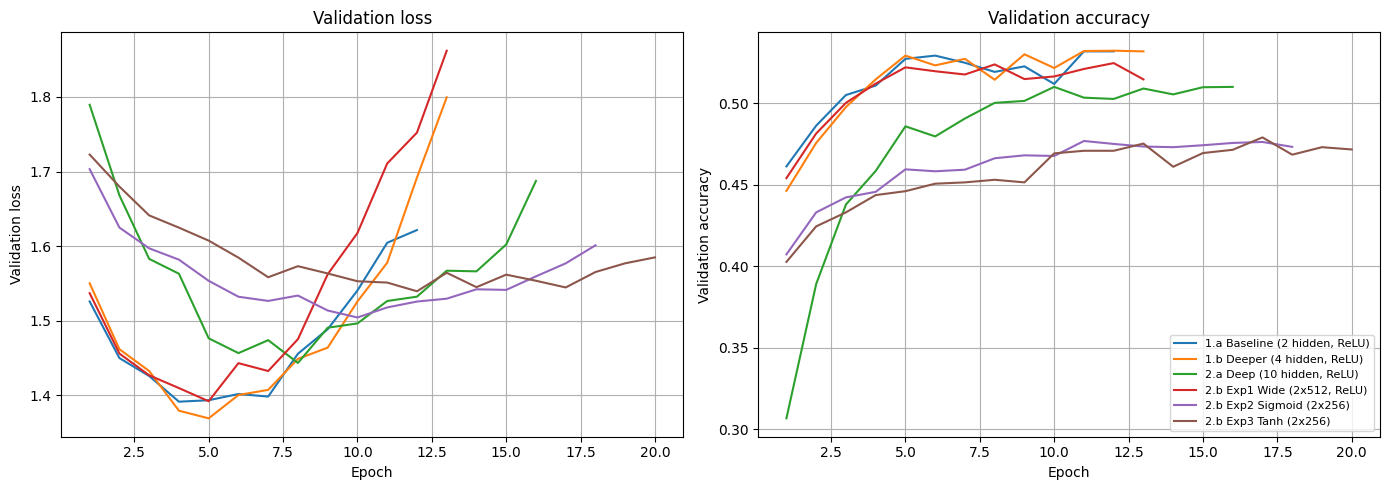

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, h in histories.items():
    axes[0].plot(range(1, len(h['val_loss']) + 1), h['val_loss'], label=name)
    axes[1].plot(range(1, len(h['val_acc']) + 1), h['val_acc'], label=name)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Validation loss'); axes[0].set_title('Validation loss')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Validation accuracy'); axes[1].set_title('Validation accuracy')
for ax in axes:
    ax.grid(True)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

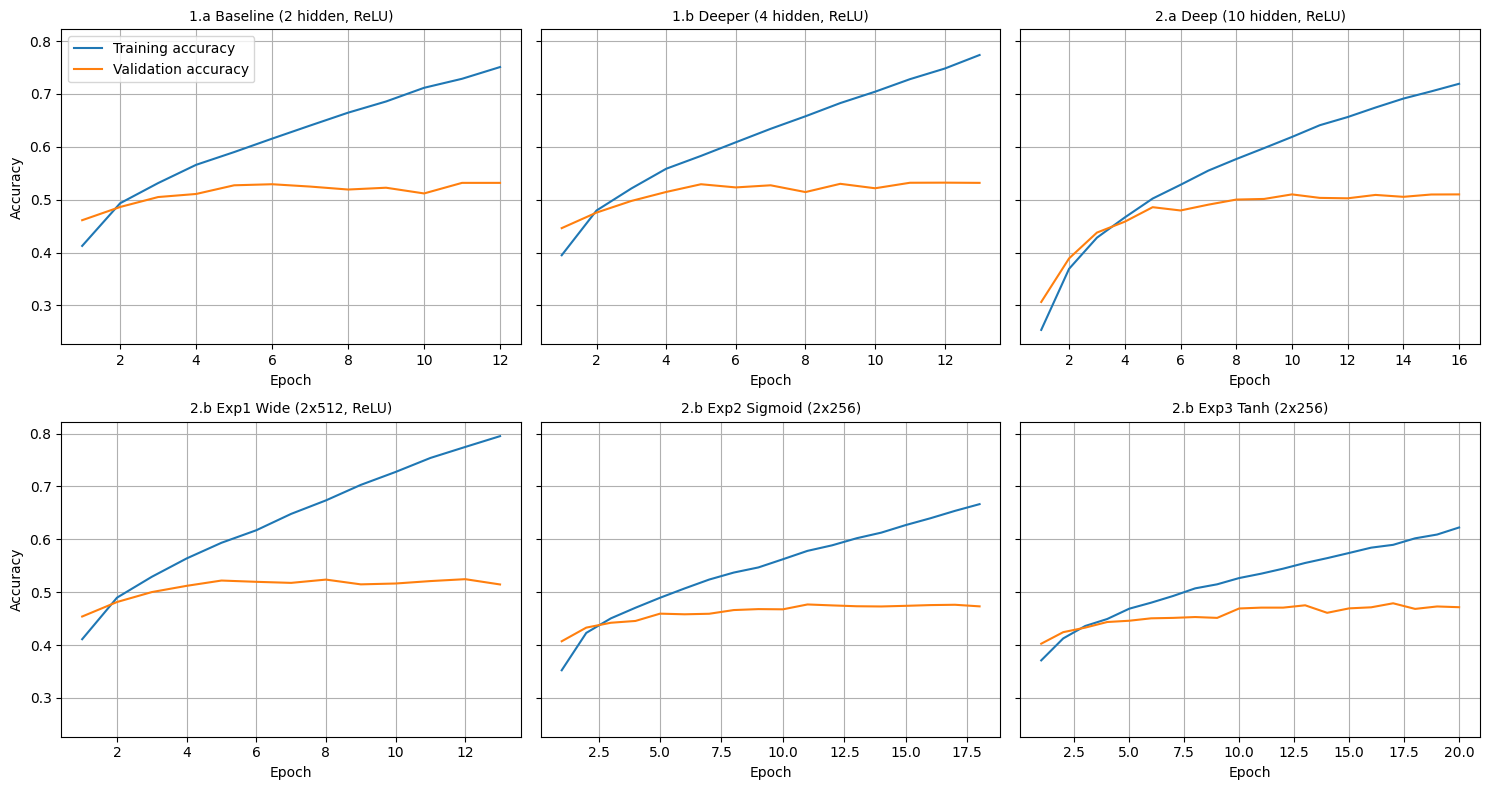

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, (name, h) in zip(axes.flat, histories.items()):
    ax.plot(range(1, len(h['train_acc']) + 1), h['train_acc'], label='Training accuracy')
    ax.plot(range(1, len(h['val_acc']) + 1), h['val_acc'], label='Validation accuracy')
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('Epoch')
    ax.grid(True)
axes[0, 0].set_ylabel('Accuracy')
axes[1, 0].set_ylabel('Accuracy')
axes[0, 0].legend()
plt.tight_layout()
plt.show()